[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vzavala/PIML_PEQ_2026/blob/main/JupyterNotebooks/PCML_Module2_Membrane.ipynb)

# Module 2 Tutorial: Mass Balances as Physics for a Membrane Separator
## Physics-Constrained Machine Learning: Concepts, Tools, and Algorithms

**Victor M. Zavala and Angan Mukherjee — University of Wisconsin-Madison**

ML models are flexible, but with **limited data** they overfit and generalize poorly. In this tutorial we predict the
outputs of a membrane separator from its inputs, and we show how **mass balances** regularize the ML model. We will:

1. Generate a small number of noisy experiments for a membrane separator with three inputs and four outputs.
2. Train a pure NN, a physics-informed NN (PINN), and a physics-constrained NN (PCNN).
3. Train a pure GP and an additive GP that uses an approximate physics model as prior mean.
4. Compare the models as a function of the number of experiments (learning curves).

### Connection to the slides (Module 2)

The pure NN, PINN, and PCNN use the same NN; they only differ in **how the mass balances enter**:
not at all (pure NN), as a penalty in the loss (PINN), or exactly in the architecture (PCNN).

### Before the workshop

    conda create -n pcml -c conda-forge python=3.11 numpy scipy matplotlib scikit-learn jupyterlab ipykernel
    conda activate pcml
    python -m pip install torch
    jupyter lab

On Google Colab, all required packages are already installed. The whole notebook runs in about one minute.

In [1]:
import time
import warnings
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, RBF

warnings.filterwarnings("ignore")
SEED = 26
torch.set_default_dtype(torch.float64)

plt.rcParams.update({
    "text.usetex": False, # Set to True if you have an external LaTeX installation
    "font.family": "serif",
    "axes.labelsize": 14,
    "axes.titlesize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 10,
})

### 1. The membrane separator

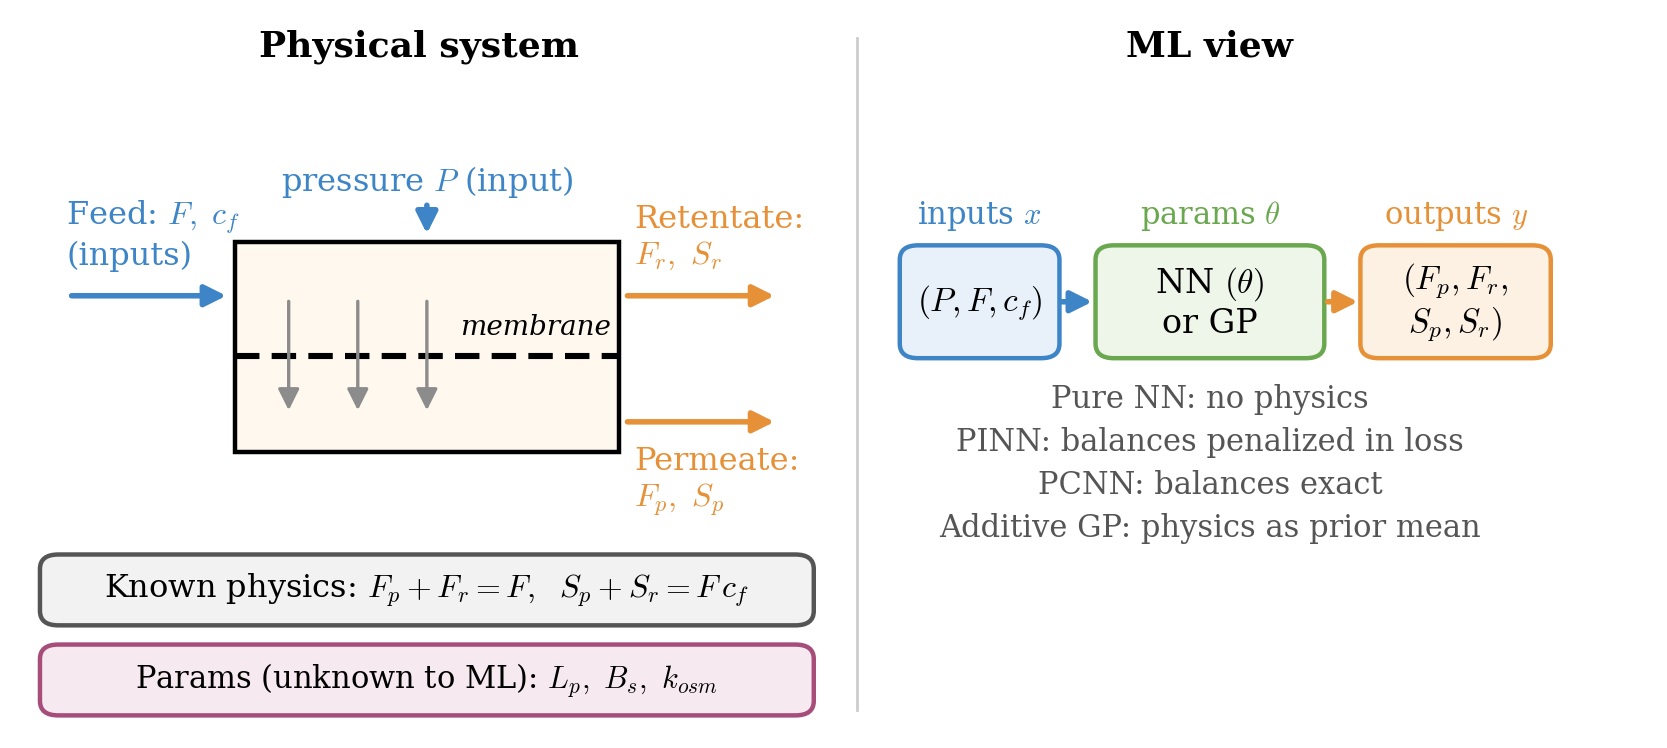

A membrane separates a liquid feed (flow $F$, solute mass fraction $c_f$) into a **permeate** and a **retentate**.
The inputs are the transmembrane pressure $P\in[5,15]$ bar, the feed flow $F\in[50,150]$ kg/h, and the feed
concentration $c_f\in[0.01,0.03]$. The outputs are the total flows $F_p,F_r$ (kg/h) and the solute flows $S_p,S_r$ (kg/h).

**Physics: mass balances.** There is no reaction, accumulation, or leak; thus, for every input:

$$F_p+F_r=F,\qquad S_p+S_r=F\,c_f$$

These balances hold exactly, but they do **not** tell us how the feed is split between permeate and retentate; this
depends on transport phenomena that we assume are unknown. The product purities are the concentrations
$c_p=S_p/F_p$ and $c_r=S_r/F_r$.

**Data generation.** We generate synthetic data with a simple solution-diffusion model (water flux driven by
$P-\pi$, with osmotic pressure $\pi$ proportional to $c_f$; solute passage decreases with water flux). The ML models do
not know this model; they only see the data and (in the hybrid models) the mass balances.

In [2]:
Lp_true, B_s, k_osm = 9.0, 6.0, 120.0     # water permeance, solute permeance, osmotic coefficient


def membrane(X, Lp=Lp_true):
    # X columns: P (bar), F (kg/h), cf (-); returns Fp, Fr, Sp, Sr (kg/h)
    P, F, cf = X[:, 0], X[:, 1], X[:, 2]
    Jw = Lp*np.maximum(P - k_osm*cf, 0.0)          # water permeation driving force
    Fp = 0.9*(1 - np.exp(-Jw/F))*F                 # permeate flow (recovery saturates)
    Sp = Fp*cf*B_s/(B_s + Fp)                      # permeate solute flow
    return np.column_stack([Fp, F - Fp, Sp, F*cf - Sp])


lo, hi = np.array([5.0, 50.0, 0.01]), np.array([15.0, 150.0, 0.03])


def sample_inputs(n, rng):
    return lo + (hi - lo)*rng.uniform(size=(n, 3))


sigma = np.array([1.5, 1.5, 0.005, 0.03])          # measurement noise of Fp, Fr, Sp, Sr (kg/h)
labels = [r"$F_p$ (kg/h)", r"$F_r$ (kg/h)", r"$S_p$ (kg/h)", r"$S_r$ (kg/h)"]

# test set to evaluate the models
X_test = sample_inputs(1000, np.random.default_rng(999))
Y_test = membrane(X_test)

### 2. Generate (limited) data

We run only $N=10$ experiments at random inputs. With three inputs and four outputs, this is very little data.

In [3]:
rng = np.random.default_rng(SEED)
N_exp = 10
X_train = sample_inputs(N_exp, rng)
Y_train = membrane(X_train) + rng.normal(size=(N_exp, 4))*sigma

print("Inputs of the experiments (P, F, cf):")
print(np.round(X_train, 3))
print("Max balance violation in the noisy data (kg/h):",
      np.abs(Y_train[:, 0] + Y_train[:, 1] - X_train[:, 1]).max().round(2))

Inputs of the experiments (P, F, cf):
[[9.91600e+00 7.34400e+01 1.10000e-02]
 [1.21290e+01 1.31312e+02 2.10000e-02]
 [1.13430e+01 6.69200e+01 2.10000e-02]
 [6.75800e+00 1.00657e+02 1.70000e-02]
 [1.46240e+01 1.01978e+02 1.40000e-02]
 [7.57300e+00 1.05039e+02 2.70000e-02]
 [8.37200e+00 1.40441e+02 1.50000e-02]
 [1.41730e+01 1.22897e+02 2.90000e-02]
 [1.45070e+01 6.60110e+01 2.40000e-02]
 [7.39800e+00 1.11383e+02 1.50000e-02]]
Max balance violation in the noisy data (kg/h): 5.21


### 3. Three NN models

All models use the same NN (three inputs, one hidden layer with 8 tanh neurons), the same scaling, and the same training
algorithm (Adam, 3000 iterations, small $\ell_2$ regularization). Only **how the mass balances enter** changes:

| Model | Prediction | Loss | Balances |
|---|---|---|---|
| Pure NN | NN predicts $(F_p,F_r,S_p,S_r)$ | $L_d(\theta)$ | Not used |
| PINN | NN predicts $(F_p,F_r,S_p,S_r)$ | $L_d(\theta)+\lambda_p L_p(\theta)$ | Penalized (approximately satisfied) |
| PCNN | NN predicts recovery ${\color{blue}R}=F_p/F$ and solute split ${\color{blue}s}=S_p/(Fc_f)$; balances give $F_r,S_r$ | $L_d(\theta)$ | Exactly satisfied |

As on the slides, the ML predictions $\hat y=(\hat F_p,\hat F_r,\hat S_p,\hat S_r)={\color{blue}\mathrm{ML}_\theta(x)}$ (shown in blue) enter
the data loss and the physics loss, summed over the observations $\omega\in\mathcal{S}$:

$$L_d(\theta)=\frac{1}{2}\sum_{\omega\in\mathcal{S}}\sum_j\left(\frac{y_{\omega j}-{\color{blue}\hat y_{\omega j}}}{\sigma_j}\right)^2,\qquad
L_p(\theta)=\frac{1}{2}\sum_{\omega\in\mathcal{S}}\left[\left(\frac{{\color{blue}\hat F_p}+{\color{blue}\hat F_r}-F}{2.1}\right)^2+\left(\frac{{\color{blue}\hat S_p}+{\color{blue}\hat S_r}-Fc_f}{0.03}\right)^2\right]_\omega$$

The code averages both losses over the observations instead of summing them, which only rescales the loss. Note that
the physics is enforced **only at the observations**, where the data already nearly satisfy the balances.

In the PCNN, the balances are part of the architecture: $\hat F_p={\color{blue}R}\,F$, $\hat S_p={\color{blue}s}\,F\,c_f$, $\hat F_r=F-\hat F_p$, and $\hat S_r=Fc_f-\hat S_p$. The NN only has
to learn two dimensionless outputs instead of four flows.

In [4]:
y_shift = torch.tensor([40.0, 60.0, 0.1, 2.0])
y_scale = torch.tensor([20.0, 20.0, 0.04, 1.0])


def scale_inputs(X):
    return torch.tensor((X - np.array([10.0, 100.0, 0.02]))/np.array([5.0, 50.0, 0.01]))


def balance_residuals(Y, X):
    # residuals of total and solute balances (scaled by their noise levels)
    X = torch.as_tensor(X)
    g_total = (Y[:, 0] + Y[:, 1] - X[:, 1])/2.1
    g_solute = (Y[:, 2] + Y[:, 3] - X[:, 1]*X[:, 2])/0.03
    return torch.stack([g_total, g_solute], dim=1)


class SmallNN(nn.Module):
    def __init__(self, n_out, n_hidden=8):
        super().__init__()
        self.hidden = nn.Linear(3, n_hidden)
        self.output = nn.Linear(n_hidden, n_out)

    def forward(self, x):
        return self.output(torch.tanh(self.hidden(x)))


def predict(mode, net, X):
    # model predictions (Fp, Fr, Sp, Sr) for each paradigm
    z = net(scale_inputs(X))
    if mode in ("pure", "pinn"):                       # NN predicts all four flows
        return y_shift + y_scale*z
    if mode == "pcnn":                                 # NN predicts R and s; balances give Fr and Sr
        Xt = torch.tensor(X)
        F, cf = Xt[:, 1], Xt[:, 2]
        R = 0.45 + 0.25*z[:, 0]                        # recovery Fp/F
        s = 0.07 + 0.04*z[:, 1]                        # solute split Sp/(F cf)
        Fp, Sp = R*F, s*F*cf
        return torch.stack([Fp, F - Fp, Sp, F*cf - Sp], dim=1)


def data_loss(Y_hat, Y_data):
    # L_d: noise-weighted squared error
    return 0.5*torch.mean(torch.sum(((Y_hat - torch.tensor(Y_data))/torch.tensor(sigma))**2, dim=1))


def physics_loss(net, mode, X_data):
    # L_p: squared balance residuals at the observations
    return 0.5*torch.mean(torch.sum(balance_residuals(predict(mode, net, X_data), X_data)**2, dim=1))


def train(mode, X_data, Y_data, lam=1.0, iters=3000, kappa=1e-3, seed=SEED):
    # train with Adam: min L_d + lam*L_p (PINN only) + kappa*||theta||^2
    torch.manual_seed(seed)
    net = SmallNN(n_out=2 if mode == "pcnn" else 4)
    optimizer = torch.optim.Adam(net.parameters(), lr=0.01)
    for it in range(iters):
        optimizer.zero_grad()
        loss = data_loss(predict(mode, net, X_data), Y_data)
        if mode == "pinn":
            loss = loss + lam*physics_loss(net, mode, X_data)
        loss = loss + kappa*sum(torch.sum(p**2) for p in net.parameters())
        loss.backward()
        optimizer.step()
    return net


t0 = time.perf_counter()
nets = {mode: train(mode, X_train, Y_train) for mode in ["pure", "pinn", "pcnn"]}
print(f"Training time for three models: {time.perf_counter() - t0:.1f} s")

Training time for three models: 3.1 s


### 4. Evaluate the NN models

We evaluate the models on 1000 test inputs. Besides the four flows, we look at the **retentate purity**
$c_r=S_r/F_r$ (a derived quantity that is often what we care about) and at the violation of the balances.

In [5]:
def evaluate(Y):
    # RMSE of each flow, RMSE of retentate purity (g/kg), and max balance violations (kg/h)
    e_flows = np.sqrt(np.mean((Y - Y_test)**2, axis=0))
    e_cr = 1e3*np.sqrt(np.mean((Y[:, 3]/Y[:, 1] - Y_test[:, 3]/Y_test[:, 1])**2))
    v_total = np.abs(Y[:, 0] + Y[:, 1] - X_test[:, 1]).max()
    v_solute = np.abs(Y[:, 2] + Y[:, 3] - X_test[:, 1]*X_test[:, 2]).max()
    return e_flows, e_cr, v_total, v_solute


with torch.no_grad():
    preds = {mode: predict(mode, net, X_test).numpy() for mode, net in nets.items()}

print(f"{'Model':6s} {'RMSE Fp':>8s} {'RMSE Sr':>8s} {'RMSE cr (g/kg)':>15s} {'max |total bal|':>16s} {'max |solute bal|':>17s}")
for lab, mode in [("Pure", "pure"), ("PINN", "pinn"), ("PCNN", "pcnn")]:
    e, ecr, vt, vs = evaluate(preds[mode])
    print(f"{lab:6s} {e[0]:8.2f} {e[3]:8.3f} {ecr:15.2f} {vt:16.2f} {vs:17.3f}")

Model   RMSE Fp  RMSE Sr  RMSE cr (g/kg)  max |total bal|  max |solute bal|
Pure       4.97    0.186            5.26            29.58             0.717
PINN       3.77    0.144            3.26            23.74             0.667
PCNN       2.94    0.016            2.26             0.00             0.000


To visualize the models, we plot predictions along a **slice** of the input space: we vary the pressure and keep
$F=100$ kg/h and $c_f=0.02$ fixed.

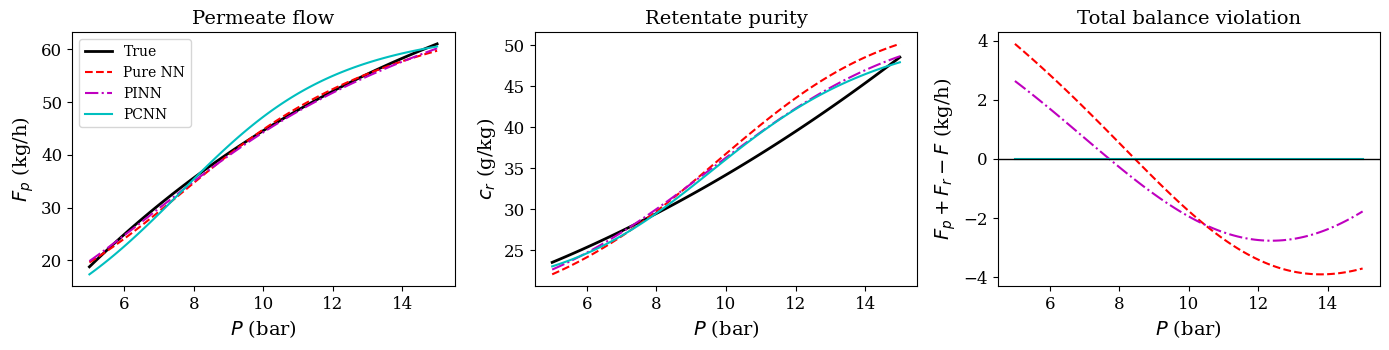

In [6]:
P_slice = np.linspace(5, 15, 101)
X_slice = np.column_stack([P_slice, 100.0*np.ones(101), 0.02*np.ones(101)])
Y_slice = membrane(X_slice)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
styles = [("Pure NN", "pure", "r--"), ("PINN", "pinn", "m-."), ("PCNN", "pcnn", "c-")]
with torch.no_grad():
    S = {mode: predict(mode, nets[mode], X_slice).numpy() for _, mode, _ in styles}
axes[0].plot(P_slice, Y_slice[:, 0], "k-", lw=2, label="True")
axes[1].plot(P_slice, 1e3*Y_slice[:, 3]/Y_slice[:, 1], "k-", lw=2, label="True")
for lab, mode, sty in styles:
    axes[0].plot(P_slice, S[mode][:, 0], sty, label=lab)
    axes[1].plot(P_slice, 1e3*S[mode][:, 3]/S[mode][:, 1], sty, label=lab)
    axes[2].plot(P_slice, S[mode][:, 0] + S[mode][:, 1] - 100.0, sty, label=lab)
axes[2].axhline(0, color="k", lw=1)
axes[0].set(xlabel="$P$ (bar)", ylabel=labels[0], title="Permeate flow")
axes[1].set(xlabel="$P$ (bar)", ylabel="$c_r$ (g/kg)", title="Retentate purity")
axes[2].set(xlabel="$P$ (bar)", ylabel="$F_p+F_r-F$ (kg/h)", title="Total balance violation")
axes[0].legend()
plt.tight_layout()
plt.show()

**Observations**

- The pure NN learns each flow independently and violates the balances by several kg/h; its retentate purity, a ratio of
  two independently predicted flows, is unreliable.
- The PINN enforces the balances only at the observations; away from them, it can still violate the balances
  (by up to about 24 kg/h on the test inputs). The PCNN satisfies them exactly for every input.
- The balances do not tell the NN how the feed is split, but they **regularize** the model: the NN has fewer things to
  learn from the data, and derived quantities such as purities become reliable.

### 5. Additive GP: approximate physics as prior mean

Suppose that we also have an **approximate transport model** (the solution-diffusion model with a water permeance that
is 15% too low). An additive GP learns the **error** of this model, $y-\mathrm{PH}(x)$, for each output; away from the data,
it reverts to the physics model (instead of a constant). We compare it with a pure GP.

Approximate physics  RMSE Fp =  4.55 kg/h, RMSE cr =  4.24 g/kg
Pure GP              RMSE Fp =  4.06 kg/h, RMSE cr =  2.64 g/kg
Additive GP          RMSE Fp =  1.53 kg/h, RMSE cr =  2.14 g/kg


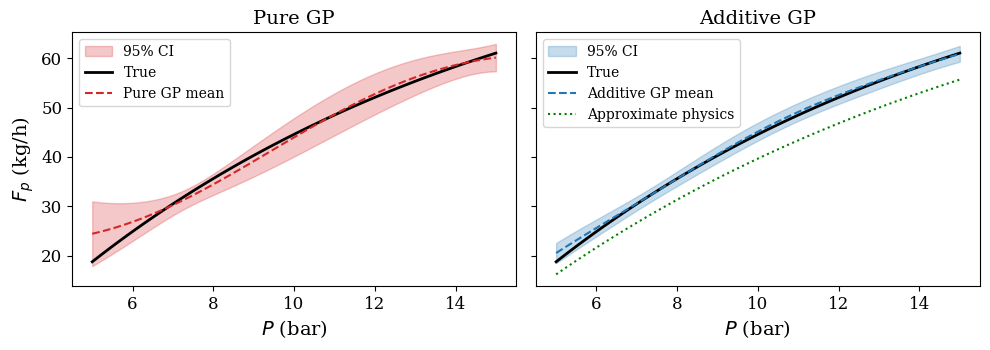

In [7]:
def gp_fit_predict(X_data, Y_data, X_eval, additive):
    # one GP per output; additive=True uses the approximate physics model as prior mean
    x_tr, x_ev = scale_inputs(X_data).numpy(), scale_inputs(X_eval).numpy()
    ph_tr, ph_ev = membrane(X_data, 0.85*Lp_true), membrane(X_eval, 0.85*Lp_true)
    mu, sd = np.zeros((len(X_eval), 4)), np.zeros((len(X_eval), 4))
    for j in range(4):
        target = Y_data[:, j] - (ph_tr[:, j] if additive else 0.0)
        kernel = ConstantKernel(1.0, (1e-3, 1e3))*RBF(np.ones(3), (1e-2, 1e2))
        gp = GaussianProcessRegressor(kernel=kernel, alpha=(sigma[j]/max(target.std(), 1e-9))**2,
                                      normalize_y=True, n_restarts_optimizer=3, random_state=SEED)
        mu[:, j], sd[:, j] = gp.fit(x_tr, target).predict(x_ev, return_std=True)
        if additive:
            mu[:, j] += ph_ev[:, j]
    return mu, sd


ph_test = membrane(X_test, 0.85*Lp_true)
gp_pure = gp_fit_predict(X_train, Y_train, X_test, additive=False)[0]
gp_add = gp_fit_predict(X_train, Y_train, X_test, additive=True)[0]
for lab, Y in [("Approximate physics", ph_test), ("Pure GP", gp_pure), ("Additive GP", gp_add)]:
    e, ecr, vt, vs = evaluate(Y)
    print(f"{lab:20s} RMSE Fp = {e[0]:5.2f} kg/h, RMSE cr = {ecr:5.2f} g/kg")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, (lab, add, col) in zip(axes, [("Pure GP", False, "tab:red"), ("Additive GP", True, "tab:blue")]):
    mu, sd = gp_fit_predict(X_train, Y_train, X_slice, additive=add)
    ax.fill_between(P_slice, mu[:, 0] - 1.96*sd[:, 0], mu[:, 0] + 1.96*sd[:, 0], color=col, alpha=0.25, label="95% CI")
    ax.plot(P_slice, Y_slice[:, 0], "k-", lw=2, label="True")
    ax.plot(P_slice, mu[:, 0], "--", color=col, label=lab + " mean")
    if add:
        ax.plot(P_slice, membrane(X_slice, 0.85*Lp_true)[:, 0], "g:", label="Approximate physics")
    ax.set(xlabel="$P$ (bar)", title=lab)
    ax.legend(loc="upper left")
axes[0].set_ylabel(labels[0])
plt.tight_layout()
plt.show()

### 6. How much data do we need? Learning curves

A single data set can be lucky or unlucky. We repeat the study for $N=5,10,20,40$ experiments (5 random designs for each
$N$) and plot the average errors. Physics matters most when data are scarce.

Learning curves computed in 53 s


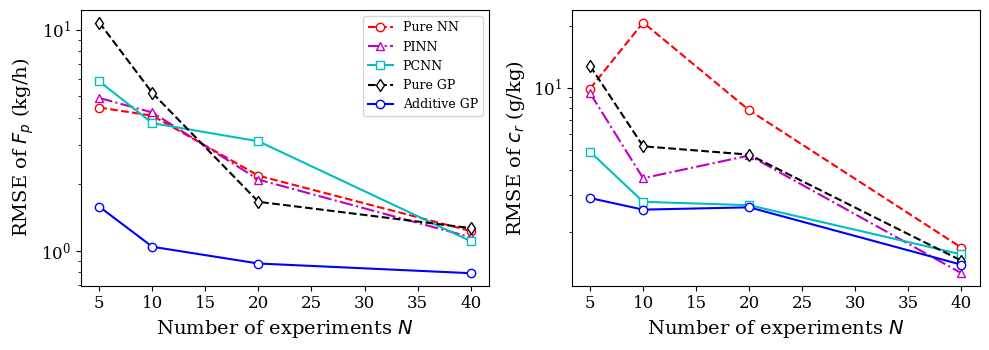

Pure NN      Fp:  4.45   4.09   2.19   1.23   |  cr:   9.92   20.81    7.79    1.67
PINN         Fp:  4.92   4.23   2.10   1.15   |  cr:   9.43    3.64    4.69    1.26
PCNN         Fp:  5.85   3.78   3.13   1.11   |  cr:   4.89    2.79    2.69    1.55
Pure GP      Fp: 10.81   5.19   1.67   1.27   |  cr:  12.80    5.20    4.74    1.45
Additive GP  Fp:  1.58   1.04   0.88   0.79   |  cr:   2.91    2.56    2.63    1.38


In [8]:
N_values = [5, 10, 20, 40]
models = ["Pure NN", "PINN", "PCNN", "Pure GP", "Additive GP"]
curve_fp = {m: [] for m in models}
curve_cr = {m: [] for m in models}
t0 = time.perf_counter()
for N in N_values:
    e_fp = {m: [] for m in models}
    e_cr = {m: [] for m in models}
    for s in range(5):
        r = np.random.default_rng(10 + s)
        X_d = sample_inputs(N, r)
        Y_d = membrane(X_d) + r.normal(size=(N, 4))*sigma
        results = {}
        for m, mode in [("Pure NN", "pure"), ("PINN", "pinn"), ("PCNN", "pcnn")]:
            net = train(mode, X_d, Y_d, seed=s)
            with torch.no_grad():
                results[m] = predict(mode, net, X_test).numpy()
        results["Pure GP"] = gp_fit_predict(X_d, Y_d, X_test, additive=False)[0]
        results["Additive GP"] = gp_fit_predict(X_d, Y_d, X_test, additive=True)[0]
        for m in models:
            e, ecr, _, _ = evaluate(results[m])
            e_fp[m].append(e[0])
            e_cr[m].append(ecr)
    for m in models:
        curve_fp[m].append(np.mean(e_fp[m]))
        curve_cr[m].append(np.mean(e_cr[m]))
print(f"Learning curves computed in {time.perf_counter() - t0:.0f} s")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
sty = {"Pure NN": "ro--", "PINN": "m^-.", "PCNN": "cs-", "Pure GP": "kd--", "Additive GP": "bo-"}
for m in models:
    axes[0].semilogy(N_values, curve_fp[m], sty[m], mfc="w", label=m)
    axes[1].semilogy(N_values, curve_cr[m], sty[m], mfc="w", label=m)
axes[0].set(xlabel="Number of experiments $N$", ylabel="RMSE of $F_p$ (kg/h)")
axes[1].set(xlabel="Number of experiments $N$", ylabel="RMSE of $c_r$ (g/kg)")
axes[0].legend(fontsize=9)
plt.tight_layout()
plt.show()

for m in models:
    print(f"{m:12s} Fp: " + "  ".join(f"{e:5.2f}" for e in curve_fp[m]) +
          "   |  cr: " + "  ".join(f"{e:6.2f}" for e in curve_cr[m]))

**Observations**

- With few experiments, the physics-based models are much more accurate, in particular for the retentate purity
  (derived from two predicted flows): the mass balances **mitigate limited data**.
- The approximate physics model makes the additive GP accurate even with five experiments.
- As data accumulate, all models improve and the gap shrinks.

### 7. Key takeaways

- Mass balances do not tell us how the feed is split, but they **regularize** ML models and make their predictions
  physically consistent (no mass is created or destroyed).
- The way physics enters changes the learning problem: the PINN needs a penalty weight $\lambda_p$ and constrains the NN
  only where the physics is evaluated; the PCNN embeds the balances in the architecture so that they hold everywhere.
- An approximate physics model (additive GP) helps even more when it is available.

### 8. Optional exercises

1. **Penalty weight.** Train the PINN with $\lambda_p=0.01$ and $\lambda_p=100$. How do the error and the balance violation change?
2. **Bounds.** In the PCNN, use `torch.sigmoid` for $R$ and $s$ so that $0\le F_p\le F$ and $0\le S_p\le Fc_f$. What changes?
3. **Constrained optimization.** The PEQ tutorial (`PEQ_Colloquium_Tutorial_1`) enforces balances on the NN weights using Ipopt. Compare both approaches.
4. **Where to enforce physics.** Evaluate the PINN physics loss also at 300 random inputs (no measurements are needed
   there). How do the accuracy and the balance violation change?
5. **Worse physics.** Use a water permeance that is 50% too low in the additive GP. Does it still help?

### 9. Note: enforcing physics at random inputs

The balances need no measurements, so a PINN can also enforce them at **random inputs** that cover the input domain
(in addition to the observations). This constrains the NN away from the data and makes it more robust. For example,
evaluating the physics loss at 300 random inputs (with the same 10 experiments and $\lambda_p$) gave RMSE of $F_p$ of
2.4 kg/h (vs. 3.8), RMSE of $S_r$ of 0.02 kg/h (vs. 0.14), and a maximum total-balance violation of 4 kg/h (vs. 24),
close to the PCNN. Exercise 4 above asks you to try this.

### References

- Mukherjee, A., and Zavala, V. M. (2026). *Physics-Constrained Machine Learning for Chemical Engineering*. Current Opinion in Chemical Engineering, 51, 101228. https://doi.org/10.1016/j.coche.2026.101228
- Mukherjee, A., and Bhattacharyya, D. (2024). On the development of steady-state and dynamic mass-constrained neural networks
  using noisy transient data. *Computers & Chemical Engineering*, 187, 108722.
- Raissi, M., Perdikaris, P., and Karniadakis, G. E. (2019). Physics-informed neural networks. *Journal of Computational Physics*, 378, 686–707.